# 02. 베이스라인 모델 (Baseline)

**목표:** 기준이 되는 모델들을 만들고 성능을 확인한다. 앞으로 개선할 때 "이 점수보다 좋아졌는가?"를 비교하는 **기준선**이 된다.

### 문제 정리
- `train.csv`: 2023-01-01 ~ 2024-06-15 (학습용)
- `TEST_00 ~ 09`: 각각 **28일치** 입력이 들어 있음 (2024-06 ~ 2025-05 사이에 약 5주 간격으로 1년에 걸쳐 분포)
- 할 일: 각 TEST의 28일 **다음 7일**을 메뉴별로 예측
- ⚠️ 규칙: 예측할 때는 **그 TEST 파일의 28일만** 사용 가능

### 이 노트북의 핵심 아이디어 ⭐
평가지표(SMAPE)는 **실제 판매량이 0인 날을 채점하지 않습니다.**
→ 채점되는 날은 "팔린 날"뿐이므로, 모델은 **"팔린다면 몇 개 팔릴까?"** 를 맞혀야 유리합니다.
→ 이 노트북에서 "모든 날로 학습" vs "팔린 날만으로 학습"을 직접 비교해 이 아이디어를 검증합니다.

### 순서
1. 데이터 준비 → 2. 평가지표 → 3. 검증 설계(계절별 3개 fold) → 4. 규칙 기반 베이스라인 → 5. LightGBM 2종 → 6. 결과 비교 → 7. 제출 파일

## 0. 환경 설정

In [1]:
# ▶ Google Colab에서만 실행되는 셀입니다 (내 컴퓨터에서는 아무 일도 안 함).
#   구글 드라이브 연결 팝업이 뜨면 '허용'을 눌러주세요.
import sys
if 'google.colab' in sys.modules:
    !pip install -q koreanize-matplotlib
    from google.colab import drive
    drive.mount('/content/drive')
# !pip install -q lightgbm   # Colab에는 보통 이미 설치되어 있음

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 17.9 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
import os
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# ---- 한글 폰트 설정 (그래프에 한글이 네모(□)로 깨지는 것 방지) ----
try:
    import koreanize_matplotlib  # Colab: 위 셀에서 pip install 필요
except ImportError:
    if platform.system() == 'Windows':
        plt.rc('font', family='Malgun Gothic')
    elif platform.system() == 'Darwin':  # macOS
        plt.rc('font', family='AppleGothic')
plt.rc('axes', unicode_minus=False)  # 마이너스(-) 기호 깨짐 방지

# ---- 경로 설정 ----
# Colab이면 구글 드라이브의 'capstone' 폴더를, 내 컴퓨터면 노트북 위 폴더(..)를 기준으로 씁니다.
import sys
IN_COLAB = 'google.colab' in sys.modules
BASE_DIR = Path('/content/drive/MyDrive/capstone') if IN_COLAB else Path('..')
DATA_DIR = Path(os.environ.get('DATA_DIR', BASE_DIR / 'data'))
FIG_DIR = Path(os.environ.get('FIG_DIR', BASE_DIR / 'figures'))
RESULT_DIR = Path(os.environ.get('RESULT_DIR', BASE_DIR / 'results'))
SUB_DIR = Path(os.environ.get('SUB_DIR', BASE_DIR / 'submissions'))
print('Colab 여부:', IN_COLAB, '| 데이터 경로:', DATA_DIR)
for d in [FIG_DIR, RESULT_DIR, SUB_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print('train.csv 존재 여부:', (DATA_DIR / 'train' / 'train.csv').exists())

Colab 여부: True | 데이터 경로: /content/drive/MyDrive/capstone/data
train.csv 존재 여부: True


In [3]:
import re
import lightgbm as lgb
print('LightGBM version:', lgb.__version__)
SEED = 42
np.random.seed(SEED)

LightGBM version: 4.6.0


In [4]:
# 한국 공휴일 목록 (2023~2025, 대체공휴일·임시공휴일 포함)
# 외부 라이브러리 없이 직접 적어두었습니다. 필요하면 `holidays` 패키지로 바꿔도 됩니다.
KR_HOLIDAYS = pd.to_datetime([
    # 2023
    '2023-01-01', '2023-01-21', '2023-01-22', '2023-01-23', '2023-01-24',
    '2023-03-01', '2023-05-05', '2023-05-27', '2023-05-29', '2023-06-06',
    '2023-08-15', '2023-09-28', '2023-09-29', '2023-09-30', '2023-10-02',
    '2023-10-03', '2023-10-09', '2023-12-25',
    # 2024
    '2024-01-01', '2024-02-09', '2024-02-10', '2024-02-11', '2024-02-12',
    '2024-03-01', '2024-04-10', '2024-05-05', '2024-05-06', '2024-05-15',
    '2024-06-06', '2024-08-15', '2024-09-16', '2024-09-17', '2024-09-18',
    '2024-10-01', '2024-10-03', '2024-10-09', '2024-12-25',
    # 2025
    '2025-01-01', '2025-01-27', '2025-01-28', '2025-01-29', '2025-01-30',
    '2025-03-01', '2025-03-03', '2025-05-05', '2025-05-06', '2025-06-03',
    '2025-06-06', '2025-08-15', '2025-10-03', '2025-10-05', '2025-10-06',
    '2025-10-07', '2025-10-08', '2025-10-09', '2025-12-25',
])
HOLIDAY_SET = set(KR_HOLIDAYS)

## 1. 데이터 준비
`train.csv`는 한 줄이 "날짜 1개 × 메뉴 1개"인 **긴(long) 형태**입니다.
예측하기 편하도록 **행 = 날짜, 열 = 메뉴**인 **넓은(wide) 형태**로 바꿉니다.

In [5]:
train = pd.read_csv(DATA_DIR / 'train' / 'train.csv')
train['영업일자'] = pd.to_datetime(train['영업일자'])
train['매출수량'] = train['매출수량'].clip(lower=0)   # 음수(반품/취소 추정) → 0

wide = (train.pivot_table(index='영업일자', columns='영업장명_메뉴명', values='매출수량', aggfunc='sum')
             .sort_index().asfreq('D').fillna(0))

MENUS = wide.columns.tolist()
VENUE_OF = {m: m.split('_', 1)[0] for m in MENUS}
VENUES = sorted(set(VENUE_OF.values()))
W = wide.values.astype(np.float32)     # (날짜 수, 메뉴 수) 숫자 배열
DATES = wide.index
print('wide 크기 (날짜 수, 메뉴 수):', wide.shape)
print('영업장:', VENUES)

wide 크기 (날짜 수, 메뉴 수): (532, 193)
영업장: ['느티나무 셀프BBQ', '담하', '라그로타', '미라시아', '연회장', '카페테리아', '포레스트릿', '화담숲주막', '화담숲카페']


## 2. 평가지표: SMAPE

$$\text{SMAPE} = \frac{1}{n}\sum \frac{2\,|실제 - 예측|}{|실제| + |예측|}$$

- **0 = 완벽, 2 = 최악, 낮을수록 좋음**
- **실제값이 0인 날은 계산에서 제외**
- 계산 순서: 메뉴별 SMAPE → 영업장 안에서 평균 → 영업장끼리 평균 (실제 대회 가중치는 비공개라 여기선 동일 가중치)

두 가지 중요한 성질이 있습니다.
1. 실제로 팔렸는데 **0으로 예측하면 무조건 2점(최악)** 이 됩니다.
2. 안 팔린 날(실제 0)에 뭘 예측하든 **점수에 영향이 없습니다.**

In [6]:
def smape_1d(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float); y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    yt, yp = y_true[mask], y_pred[mask]
    return np.mean(2 * np.abs(yt - yp) / (np.abs(yt) + np.abs(yp)))


def venue_smape(T, P):
    """T, P: (예측한 날 수, 메뉴 수) 배열. 반환: (전체 점수, 영업장별 점수 dict)"""
    scores = {}
    for v in VENUES:
        idx = [i for i, m in enumerate(MENUS) if VENUE_OF[m] == v]
        s = [smape_1d(T[:, i], P[:, i]) for i in idx]
        s = [x for x in s if not np.isnan(x)]
        if s:
            scores[v] = float(np.mean(s))
    return float(np.mean(list(scores.values()))), scores

print(smape_1d([10, 0, 5], [10, 3, 5]))   # 0.0 → 실제 0인 날은 무시됨
print(smape_1d([10], [0]))                # 2.0 → 팔렸는데 0 예측 = 최악

0.0
2.0


## 3. 검증 설계: 계절별 3개 fold (시간 순서 지키기)
TEST 구간이 **1년 전체(여름·가을·겨울·봄)** 에 퍼져 있으므로, 검증도 여러 계절에서 해야 믿을 수 있습니다.
각 fold는 **그 이전 데이터로만 학습**하고 해당 기간을 예측합니다 (Expanding-window Time-Series Split).

| fold | 학습에 쓰는 데이터 | 검증 기간 | 특징 |
|------|-----------------|-----------|------|
| 1 | ~2023-09 | 2023-10 ~ 2023-12 | 가을 성수기 → 겨울 시즌 시작 |
| 2 | ~2023-12 | 2024-01 ~ 2024-03 | 겨울 성수기 → 시즌 종료 |
| 3 | ~2024-03 | 2024-04 ~ 2024-06 | 봄 |

각 검증 기간 안에서 **7일마다** "앞 28일 → 다음 7일" 예측을 반복합니다.

In [7]:
INPUT_LEN, HORIZON = 28, 7
FOLDS = [('2023-10-01', '2023-12-31'),
         ('2024-01-01', '2024-03-31'),
         ('2024-04-01', '2024-06-09')]

def fold_origins(val_start, val_end):
    """origin = 예측 첫날의 행 번호. 학습 origin은 정답 7일이 검증 시작 전에 끝나야 함 (누수 방지)."""
    vs, ve = DATES.get_loc(pd.Timestamp(val_start)), DATES.get_loc(pd.Timestamp(val_end))
    val_o = list(range(vs, ve - HORIZON + 2, 7))
    train_o = list(range(INPUT_LEN, vs - HORIZON + 1))
    return train_o, val_o

for a, b in FOLDS:
    tr, va = fold_origins(a, b)
    print(f'검증 {a}~{b} | 학습 기준일 {len(tr)}개 | 검증 창 {len(va)}개')

검증 2023-10-01~2023-12-31 | 학습 기준일 239개 | 검증 창 13개
검증 2024-01-01~2024-03-31 | 학습 기준일 331개 | 검증 창 13개
검증 2024-04-01~2024-06-09 | 학습 기준일 422개 | 검증 창 10개


## 4. 규칙 기반 베이스라인 (머신러닝 없음)

| 이름 | 방법 | 의도 |
|------|------|------|
| A. 최근 7일 평균 | 최근 7일 평균을 7일 내내 예측 | 가장 흔한 단순 예측 |
| B. 4주 같은 요일 평균 | 최근 4주 중 같은 요일 4개 값 평균 | 요일 패턴 반영 |
| C. 판매일 중앙값 ⭐ | 최근 28일 중 **팔린 날만** 모아 중앙값 (최소 1) | "팔린다면 몇 개?" — 평가지표 맞춤 |

In [8]:
def rule_last7_mean(x):          # x: (28, 메뉴 수)
    return np.repeat(x[-7:].mean(0)[None, :], HORIZON, axis=0)

def rule_dow_mean(x):
    return x.reshape(4, 7, -1).mean(0)

def rule_sold_median(x):
    sold = np.where(x > 0, x, np.nan)
    with np.errstate(all='ignore'):
        med = np.nanmedian(sold, axis=0)          # 한 번도 안 팔렸으면 NaN
    med = np.maximum(np.nan_to_num(med), 1)       # NaN → 0 → 최소 1
    return np.repeat(med[None, :], HORIZON, axis=0)

RULES = {'A. 최근 7일 평균': rule_last7_mean,
         'B. 4주 같은 요일 평균': rule_dow_mean,
         'C. 판매일 중앙값': rule_sold_median}

results = {}      # results[모델이름] = [fold1 점수, fold2 점수, fold3 점수]
for name, fn in RULES.items():
    for a, b in FOLDS:
        _, val_o = fold_origins(a, b)
        T = np.concatenate([W[o:o + HORIZON] for o in val_o])
        P = np.concatenate([fn(W[o - INPUT_LEN:o]) for o in val_o])
        results.setdefault(name, []).append(venue_smape(T, P)[0])
    print(f'{name:16s} fold별 {np.round(results[name], 4)} → 평균 {np.mean(results[name]):.4f}')

A. 최근 7일 평균      fold별 [0.7409 1.0746 0.8049] → 평균 0.8735
B. 4주 같은 요일 평균   fold별 [0.8805 1.056  0.8851] → 평균 0.9405
C. 판매일 중앙값       fold별 [0.6264 0.8176 0.5606] → 평균 0.6682


> 📝 **여기서 첫 번째 인사이트가 나옵니다.** A와 C를 비교해 보세요.
> 모델 없이 "무엇을 예측해야 하는지"만 바꿨는데 점수가 크게 달라진다면, **평가지표를 이해하는 것 자체가 핵심 전략**이라는 뜻입니다.

## 5. LightGBM 베이스라인

### 5-1. 피처 만들기
각 **(기준일, 메뉴, h일 뒤)** 조합이 한 줄(샘플)이 됩니다. 모든 피처는 **입력 28일 + 예측일의 달력 정보**로만 만듭니다 → TEST에서도 똑같이 만들 수 있고 규칙에도 맞습니다.

| 피처 | 내용 |
|------|------|
| `lag_1`~`lag_28` | 1~28일 전 판매량 |
| `mean_7/14/28` | 최근 평균 |
| `sold_mean_7/14/28`, `sold_ratio_7/14/28`, `sold_median_28` | **팔린 날만의** 평균·중앙값, 팔린 날 비율 |
| `std_28`, `max_28`, `days_since_sale` | 변동성, 최대값, 마지막 판매 후 경과일 |
| `same_dow_last`, `same_dow_mean4`, `same_dow_sold_ratio` | 예측일과 **같은 요일**의 과거 값 |
| `h`, `dow`, `month`, `dayofyear`, `is_weekend`, `is_holiday` | 예측일의 달력 정보 (시즌 파악용) |
| `menu`, `venue` | 메뉴·영업장 (범주형) |

In [9]:
MENU_CAT = pd.CategoricalDtype(MENUS)
VENUE_CAT = pd.CategoricalDtype(VENUES)

def make_features(inp, start_date):
    """inp: (28, 메뉴 수) — 마지막 행이 예측 전날.  start_date: 예측 첫날.
       반환: 7 × 메뉴 수 행 (순서: h=1 전체 메뉴, h=2 전체 메뉴, ...)"""
    x = np.asarray(inp, dtype=np.float32).T                     # (메뉴 수, 28)
    F = {f'lag_{k}': x[:, INPUT_LEN - k] for k in range(1, INPUT_LEN + 1)}
    for w in (7, 14, 28):
        y = x[:, -w:]; cnt = (y > 0).sum(1)
        F[f'mean_{w}'] = y.mean(1)
        F[f'sold_mean_{w}'] = np.where(cnt > 0, y.sum(1) / np.maximum(cnt, 1), 0)
        F[f'sold_ratio_{w}'] = cnt / w
    with np.errstate(all='ignore'):
        F['sold_median_28'] = np.nan_to_num(np.nanmedian(np.where(x > 0, x, np.nan), axis=1))
    F['std_28'] = x.std(1)
    F['max_28'] = x.max(1)
    F['days_since_sale'] = np.array([INPUT_LEN - np.nonzero(r)[0][-1] if r.any() else INPUT_LEN + 1 for r in x])
    base = pd.DataFrame(F)
    base['menu'] = pd.Categorical(MENUS, dtype=MENU_CAT)
    base['venue'] = pd.Categorical([VENUE_OF[m] for m in MENUS], dtype=VENUE_CAT)

    frames = []
    for h in range(1, HORIZON + 1):
        d = start_date + pd.Timedelta(days=h - 1)
        f = base.copy()
        f['h'] = h; f['dow'] = d.dayofweek; f['month'] = d.month; f['dayofyear'] = d.dayofyear
        f['is_weekend'] = int(d.dayofweek >= 5); f['is_holiday'] = int(d in HOLIDAY_SET)
        idx = [h - 1, h + 6, h + 13, h + 20]                   # 입력 중 예측일과 같은 요일 위치
        f['same_dow_last'] = x[:, h + 20]
        f['same_dow_mean4'] = x[:, idx].mean(1)
        f['same_dow_sold_ratio'] = (x[:, idx] > 0).mean(1)
        frames.append(f)
    return pd.concat(frames, ignore_index=True)


def build_dataset(origins):
    X = pd.concat([make_features(W[o - INPUT_LEN:o], DATES[o]) for o in origins], ignore_index=True)
    y = np.concatenate([W[o:o + HORIZON].reshape(-1) for o in origins])
    return X, y

### 5-2. 두 가지 방식으로 학습해서 비교
- **LGBM-전체:** 모든 샘플로 학습 (일반적인 방법)
- **LGBM-판매일 ⭐:** 정답이 0보다 큰 샘플만으로 학습 → "팔린다면 몇 개?"를 학습

둘 다 타깃은 `log1p(판매량)`으로 학습하고(큰 값에 휘둘리지 않게), 예측 후 `expm1`로 되돌립니다.
검증 점수를 속이지 않도록 early stopping 없이 **고정된 반복 횟수**를 씁니다.

In [10]:
PARAMS = dict(objective='regression', learning_rate=0.05, n_estimators=600,
              num_leaves=63, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              random_state=SEED, verbose=-1)

def train_lgbm(X, y, sold_only):
    mask = (y > 0) if sold_only else np.ones(len(y), dtype=bool)
    model = lgb.LGBMRegressor(**PARAMS)
    model.fit(X[mask], np.log1p(y[mask]))
    return model

def predict(model, X):
    return np.clip(np.expm1(model.predict(X)), 0, None)

venue_detail = {}   # 영업장별 점수 저장 (오차 분석용)
for fi, (a, b) in enumerate(FOLDS, 1):
    train_o, val_o = fold_origins(a, b)
    X_tr, y_tr = build_dataset(train_o)
    X_va, y_va = build_dataset(val_o)
    T = y_va.reshape(-1, len(MENUS))
    for name, sold_only in [('D. LGBM-전체', False), ('E. LGBM-판매일', True)]:
        model = train_lgbm(X_tr, y_tr, sold_only)
        P = predict(model, X_va).reshape(-1, len(MENUS))
        total, by_v = venue_smape(T, P)
        results.setdefault(name, []).append(total)
        venue_detail[(name, fi)] = by_v
        print(f'fold{fi} {name:14s} SMAPE = {total:.4f}')

fold1 D. LGBM-전체     SMAPE = 0.8820
fold1 E. LGBM-판매일    SMAPE = 0.6375
fold2 D. LGBM-전체     SMAPE = 0.7320
fold2 E. LGBM-판매일    SMAPE = 0.5081
fold3 D. LGBM-전체     SMAPE = 0.7664
fold3 E. LGBM-판매일    SMAPE = 0.5214


## 6. 결과 비교

,fold1,fold2,fold3,평균
E. LGBM-판매일,0.6375,0.5081,0.5214,0.5557
C. 판매일 중앙값,0.6264,0.8176,0.5606,0.6682
D. LGBM-전체,0.8820,0.7320,0.7664,0.7935
A. 최근 7일 평균,0.7409,1.0746,0.8049,0.8735
B. 4주 같은 요일 평균,0.8805,1.0560,0.8851,0.9405


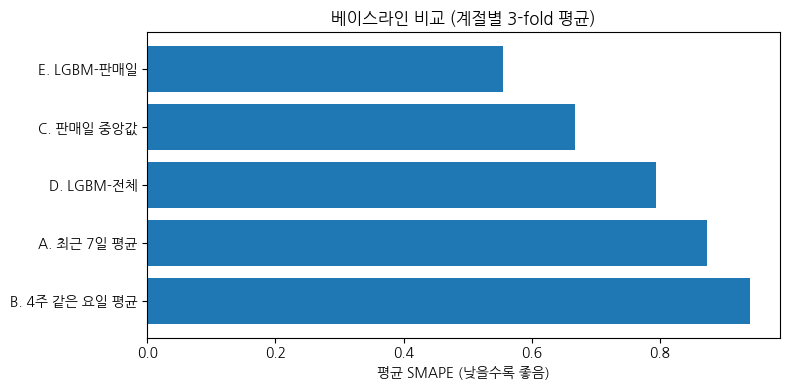

In [11]:
res_df = pd.DataFrame(results, index=[f'fold{i}' for i in range(1, len(FOLDS) + 1)]).T
res_df['평균'] = res_df.mean(1)
res_df = res_df.sort_values('평균').round(4)
display(res_df)
res_df.to_csv(RESULT_DIR / 'baseline_scores.csv', encoding='utf-8-sig')

plt.figure(figsize=(8, 4))
plt.barh(res_df.index[::-1], res_df['평균'][::-1])
plt.xlabel('평균 SMAPE (낮을수록 좋음)'); plt.title('베이스라인 비교 (계절별 3-fold 평균)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'baseline_01_scores.png', dpi=120); plt.show()

In [12]:
# 영업장별 점수 (가장 좋은 LightGBM 기준) → 어디서 많이 틀리는가?
vdf = pd.DataFrame({f'fold{fi}': venue_detail[('E. LGBM-판매일', fi)] for fi in range(1, len(FOLDS) + 1)})
vdf['평균'] = vdf.mean(1)
display(vdf.sort_values('평균', ascending=False).round(3))

,fold1,fold2,fold3,평균
화담숲카페,0.653,0.847,0.594,0.698
포레스트릿,0.808,0.425,0.657,0.630
담하,0.704,0.552,0.549,0.602
카페테리아,0.711,0.437,0.590,0.579
느티나무 셀프BBQ,0.668,0.480,0.532,0.560
라그로타,0.590,0.526,0.509,0.542
미라시아,0.617,0.503,0.500,0.540
화담숲주막,0.528,0.470,0.431,0.477
연회장,0.458,0.332,0.331,0.374


## 7. TEST 예측 & 제출 파일
train 전체(판매일 샘플)로 다시 학습한 뒤, 각 TEST의 28일로 7일을 예측합니다.

최종 모델 학습 완료 | 학습 행 수: 319914


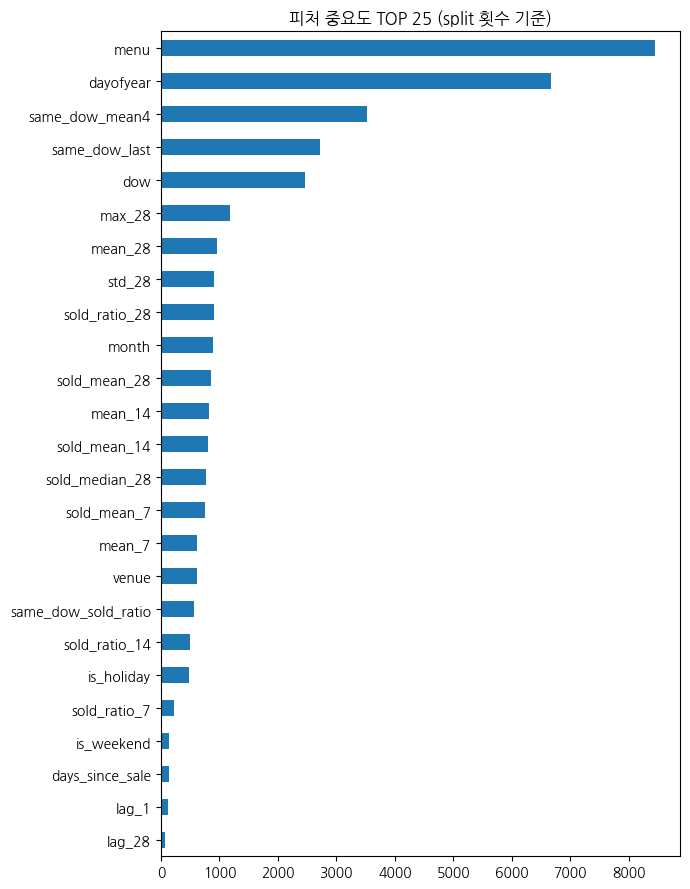

In [13]:
all_o = list(range(INPUT_LEN, len(DATES) - HORIZON + 1))
X_all, y_all = build_dataset(all_o)
final_model = train_lgbm(X_all, y_all, sold_only=True)
print('최종 모델 학습 완료 | 학습 행 수:', int((y_all > 0).sum()))

imp = pd.Series(final_model.feature_importances_, index=X_all.columns).sort_values()
plt.figure(figsize=(7, 9)); imp.tail(25).plot(kind='barh')
plt.title('피처 중요도 TOP 25 (split 횟수 기준)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'baseline_02_feature_importance.png', dpi=120); plt.show()

In [14]:
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
sub = sample.set_index('영업일자').astype(float)
cols = [m for m in MENUS if m in sub.columns]

test_files = sorted((DATA_DIR / 'test').glob('*TEST_*.csv'))
for f in test_files:
    tid = re.search(r'TEST_\d+', f.name).group()          # 파일명에서 'TEST_00' 추출
    t = pd.read_csv(f)
    t['영업일자'] = pd.to_datetime(t['영업일자'])
    t['매출수량'] = t['매출수량'].clip(lower=0)
    tw = (t.pivot_table(index='영업일자', columns='영업장명_메뉴명', values='매출수량', aggfunc='sum')
            .sort_index().asfreq('D').reindex(columns=MENUS).fillna(0)).iloc[-INPUT_LEN:]
    start = tw.index.max() + pd.Timedelta(days=1)
    pred = predict(final_model, make_features(tw.values, start)).reshape(HORIZON, len(MENUS))
    for h in range(1, HORIZON + 1):
        sub.loc[f'{tid}+{h}일', cols] = pd.Series(pred[h - 1], index=MENUS)[cols].values
    print(tid, '| 입력:', tw.index.min().date(), '~', tw.index.max().date())

sub.reset_index().to_csv(SUB_DIR / 'baseline_lgbm_sold.csv', index=False, encoding='utf-8-sig')
print('저장 완료:', (SUB_DIR / 'baseline_lgbm_sold.csv').resolve())

TEST_00 | 입력: 2024-06-16 ~ 2024-07-13
TEST_01 | 입력: 2024-07-21 ~ 2024-08-17
TEST_02 | 입력: 2024-08-25 ~ 2024-09-21
TEST_03 | 입력: 2024-09-29 ~ 2024-10-26
TEST_04 | 입력: 2024-11-03 ~ 2024-11-30
TEST_05 | 입력: 2024-12-08 ~ 2025-01-04
TEST_06 | 입력: 2025-01-12 ~ 2025-02-08
TEST_07 | 입력: 2025-02-16 ~ 2025-03-15
TEST_08 | 입력: 2025-03-23 ~ 2025-04-19
TEST_09 | 입력: 2025-04-27 ~ 2025-05-24
저장 완료: /content/drive/MyDrive/capstone/submissions/baseline_lgbm_sold.csv


## 8. 결과 기록 ✍️

| 모델 | fold1 | fold2 | fold3 | 평균 SMAPE ↓ |
|------|:----:|:----:|:----:|:----:|
| **E. LGBM-판매일** | 0.6375 | 0.5081 | 0.5214 | **0.5557** |
| C. 판매일 중앙값 | 0.6264 | 0.8176 | 0.5606 | 0.6682 |
| D. LGBM-전체 | 0.8820 | 0.7320 | 0.7664 | 0.7935 |
| A. 최근 7일 평균 | 0.7409 | 1.0746 | 0.8049 | 0.8735 |
| B. 4주 같은 요일 평균 | 0.8805 | 1.0560 | 0.8851 | 0.9405 |

- 학습 데이터를 "판매일"로 바꾸는 것만으로 LightGBM 0.794 → 0.556 (평가지표 이해가 핵심)
- 최고 규칙(C) 대비 약 17%, 7일 평균(A) 대비 약 36% 오차 감소
- fold1(가을→겨울 시작)은 학습 데이터에 해당 계절이 없어 규칙보다 약간 나쁨
- 오차가 큰 영업장: 화담숲카페(0.698, 3월 재개장), 포레스트릿(fold1 0.808, 스키 시즌 시작) → 시즌 전환 구간이 약점